# Portfolio Management - Group Work Project 3: Denoising, Hierarchical Risk Parity and Combinatorial Purged Cross-Validation

### Step 1

In [70]:
import yfinance as yf
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

In [71]:
# Define the securities and period
tickers = [
    "AAPL",     # Apple
    "AMZN",     # Amazon
    "BA",       # Boeing
    "BTC-USD",  # Bitcoin
    "F",        # Ford
    "GC=F",     # Gold
    "GOOGL",    # Google
    "META",     # Meta
    "NVDA",     # Nvidia
    "TSLA"      # Tesla
  ]

start_date = "2024-01-01"
end_date = "2025-06-30"

# Download weekly data (adjusted close prices)
data = yf.download(tickers, start=start_date, end=end_date)

if 'Adj Close' in data.columns.get_level_values(0):
    prices = data['Adj Close']
elif 'Close' in data.columns.get_level_values(0):
    prices = data['Close']

# Check if we have data for all tickers
print(f"\nData shape: {prices.shape}")
print('BTC has prices on Saturday and Sunday')

# Drop rows have no stock prices (Remove BTC prices on Saturday and Sunday)
prices = prices.dropna()

# Calculate weekly returns
returns = prices.pct_change().dropna()

print('\nData after cleaning')
print(f"Returns shape: {returns.shape}")

[*********************100%***********************]  10 of 10 completed



Data shape: (546, 10)
BTC has prices on Saturday and Sunday

Data after cleaning
Returns shape: (372, 10)


In [72]:
prices

Ticker,AAPL,AMZN,BA,BTC-USD,F,GC=F,GOOGL,META,NVDA,TSLA
Date,,,,,,,,,,
2024-01-02,183.7313,149.9300,251.7600,44957.9688,10.4672,2064.3999,137.0374,343.5936,48.1386,248.4200
2024-01-03,182.3556,148.4700,243.9100,42848.1758,10.0799,2034.2000,137.7812,341.7878,47.5399,238.4500
2024-01-04,180.0397,144.5700,244.9400,44179.9219,10.0540,2042.3000,135.2720,344.4172,47.9687,237.9300
2024-01-05,179.3171,145.2400,249.0000,44162.6914,10.2004,2042.4000,134.6174,349.2096,49.0670,237.4900
2024-01-08,183.6521,149.1000,229.0000,46970.5039,10.3037,2026.6000,137.7019,355.8673,52.2211,240.4500
...,...,...,...,...,...,...,...,...,...,...
2025-06-23,200.8887,208.4700,201.3100,105577.7734,10.3739,3377.7000,164.8185,696.8934,144.1460,348.6800
2025-06-24,199.6923,212.7700,200.9400,106045.6328,10.3546,3317.3999,166.3949,710.5313,147.8754,340.4700
2025-06-25,200.9485,211.9900,198.9000,107361.2578,10.1134,3327.1001,170.2961,707.0195,154.2844,327.5500


In [73]:
# Calculate mean returns and covariance matrix
mean_returns = returns.mean().values
cov_matrix = returns.cov().values
n_assets = len(tickers)

print("\nMean daily returns (%):")
print((mean_returns * 100).round(4))

print("\nAnnualized volatility (%):")
annual_vol = np.sqrt(252) * returns.std()
print((annual_vol * 100).round(2))


Mean daily returns (%):
[ 0.0408  0.127  -0.0144  0.2873  0.025   0.1299  0.0894  0.2327  0.3817
  0.1621]

Annualized volatility (%):
Ticker
AAPL      29.7900
AMZN      31.7800
BA        38.0000
BTC-USD   52.4500
F         35.8600
GC=F      17.2200
GOOGL     30.9000
META      38.8700
NVDA      56.1300
TSLA      68.3900
dtype: float64


In [74]:
# Portfolio optimization functions
def portfolio_variance(weights, cov_matrix):
    """Calculate portfolio variance"""
    return np.dot(weights.T, np.dot(cov_matrix, weights))

def portfolio_return(weights, mean_returns):
    """Calculate portfolio expected return"""
    return np.dot(weights, mean_returns)

def negative_sharpe_ratio(weights, mean_returns, cov_matrix, rf_rate):
    """Negative Sharpe ratio (to minimize)"""
    port_return = portfolio_return(weights, mean_returns)
    port_vol = np.sqrt(portfolio_variance(weights, cov_matrix))
    sharpe = (port_return - rf_rate) / port_vol
    return -sharpe

In [75]:
# Define constraints: sum of weights = 1
constraints = [{'type': 'eq', 'fun': lambda x: np.sum(x) - 1}]

# Define bounds: 0 ≤ weight ≤ 0.15 (no short-selling, max 15%)
bounds = [(0, 0.15) for _ in range(n_assets)]

# Initial guess (equal weights but respecting max constraint)
initial_weights = np.ones(n_assets) / n_assets
# Ensure initial weights don't exceed 15%
initial_weights = np.minimum(initial_weights, 0.15)
initial_weights = initial_weights / np.sum(initial_weights)  # Renormalize


In [76]:
# Maximum Sharpe Ratio Portfolio with 15% max weight constraint
print("MAXIMUM SHARPE RATIO PORTFOLIO")
print("Constraint: short selling is not allowed and no asset can be more than 15%")

# Use the same bounds and constraints
risk_free_rate = 0.03  # 3% annual risk-free rate
daily_rf = risk_free_rate / 252

# Optimize for MSRP
msrp_result = minimize(
    fun=negative_sharpe_ratio,
    x0=initial_weights,
    args=(mean_returns, cov_matrix, daily_rf),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'ftol': 1e-10, 'maxiter': 1000}
)

msrp_weights = msrp_result.x
msrp_variance = portfolio_variance(msrp_weights, cov_matrix)
msrp_volatility = np.sqrt(msrp_variance)
msrp_expected_return = portfolio_return(msrp_weights, mean_returns)
msrp_sharpe = (msrp_expected_return - daily_rf) / msrp_volatility

print(f"Optimization successful: {msrp_result.success}")
print(f"Message: {msrp_result.message}")
print(f"Assumed Annual Risk-free Rate: {risk_free_rate*100:.1f}%")

# Display MSRP weights
print("\n   MSRP Weights with 15% constraint:")
total_weight = 0
for i, ticker in enumerate(tickers):
    weight = msrp_weights[i]
    total_weight += weight
    print(f"   {ticker:<6}: {weight:.4f} ({weight*100:6.2f}%)")

print(f"\n Total weight: {total_weight:.8f}")

MAXIMUM SHARPE RATIO PORTFOLIO
Constraint: short selling is not allowed and no asset can be more than 15%
Optimization successful: True
Message: Optimization terminated successfully
Assumed Annual Risk-free Rate: 3.0%

   MSRP Weights with 15% constraint:
   AAPL  : 0.0354 (  3.54%)
   AMZN  : 0.1500 ( 15.00%)
   BA    : 0.0000 (  0.00%)
   BTC-USD: 0.1500 ( 15.00%)
   F     : 0.0646 (  6.46%)
   GC=F  : 0.1500 ( 15.00%)
   GOOGL : 0.1500 ( 15.00%)
   META  : 0.1500 ( 15.00%)
   NVDA  : 0.1500 ( 15.00%)
   TSLA  : 0.0000 (  0.00%)

 Total weight: 1.00000000


## Step 3

In [77]:
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import squareform
import warnings
warnings.filterwarnings('ignore')

In [78]:
# PART 1: DENOISING FUNCTIONS

def marchenko_pastur_pdf(var, q, pts):
    """Generate Marchenko-Pastur distribution"""
    emax = var * (1 + np.sqrt(1.0/q)) ** 2
    emin = var * (1 - np.sqrt(1.0/q)) ** 2

    step = (emax - emin) / pts
    e_values = np.arange(emin, emax, step)

    mpdf = (q / (2 * np.pi * var * e_values)) * np.sqrt((emax - e_values) * (e_values - emin))
    return e_values, mpdf

def denoise_covariance(cov_matrix, returns, verbose=False):
    """Denoise covariance matrix using RMT"""
    # Add small regularization to ensure positive definiteness
    cov_matrix = cov_matrix + 1e-8 * np.eye(len(cov_matrix))

    # Calculate correlation matrix
    std = np.sqrt(np.diag(cov_matrix))
    std = np.where(std < 1e-8, 1e-8, std)  # Prevent division by zero
    corr = cov_matrix / np.outer(std, std)
    corr = np.clip(corr, -1, 1)  # Clip to valid correlation range

    # Get eigenvalues and eigenvectors
    e_val, e_vec = np.linalg.eigh(corr)
    e_val = np.real(e_val)
    e_val = np.clip(e_val, 1e-8, None)  # Ensure positive eigenvalues
    idx = e_val.argsort()[::-1]
    e_val = e_val[idx]
    e_vec = e_vec[:, idx]

    # Calculate Marchenko-Pastur threshold
    T, N = returns.shape
    q = T / N

    # Maximum eigenvalue for noise
    e_max = (1 + np.sqrt(1.0/q)) ** 2

    # Find number of signal eigenvalues
    n_facts = sum(e_val > e_max)
    n_facts = max(1, min(n_facts, N-1))  # At least 1, at most N-1

    if verbose:
        print(f"\nDenoising Results:")
        print(f"  T={T}, N={N}, q={q:.4f}")
        print(f"  Noise threshold (λ_max): {e_max:.4f}")
        print(f"  Signal eigenvalues: {n_facts} (out of {N})")
        if n_facts > 0:
            print(f"  Signal eigenvalues > threshold: {e_val[:n_facts].round(4)}")

    # Constant residual eigenvalue method (CREM)
    e_val_denoised = e_val.copy()

    # Average the noise eigenvalues
    if n_facts < N:
        avg_noise = np.mean(e_val[n_facts:])
        e_val_denoised[n_facts:] = avg_noise

    # Reconstruct denoised correlation matrix
    corr_denoised = e_vec @ np.diag(e_val_denoised) @ e_vec.T

    # Ensure symmetry
    corr_denoised = (corr_denoised + corr_denoised.T) / 2

    # Clip diagonal to exactly 1
    np.fill_diagonal(corr_denoised, 1.0)

    # Convert back to covariance matrix
    cov_denoised = corr_denoised * np.outer(std, std)

    # Ensure final covariance matrix is symmetric and positive definite
    cov_denoised = (cov_denoised + cov_denoised.T) / 2

    return cov_denoised, n_facts, e_val, e_val_denoised

In [79]:
# PART 2: CLUSTERING (HRP) FUNCTIONS

def correlation_distance(corr):
    """Convert correlation to distance"""
    corr = np.clip(corr, -1, 1)  # Ensure valid correlation
    # Ensure symmetry
    corr = (corr + corr.T) / 2
    # Calculate distance
    dist = np.sqrt(2 * (1 - corr))
    # Ensure symmetry and no negative values
    dist = (dist + dist.T) / 2
    dist = np.clip(dist, 0, 2)  # Distance should be between 0 and 2
    return dist

def get_quasi_diag(link):
    """Quasi-diagonalization of covariance matrix"""
    try:
        link = link.astype(int)
        sort_ix = pd.Series([link[-1, 0], link[-1, 1]])
        num_items = link[-1, 3]

        while sort_ix.max() >= num_items:
            sort_ix.index = range(0, sort_ix.shape[0] * 2, 2)
            df0 = sort_ix[sort_ix >= num_items]
            if len(df0) == 0:
                break
            i = df0.index
            j = df0.values - num_items
            # Ensure j is within bounds
            j = np.clip(j, 0, link.shape[0]-1)
            sort_ix[i] = link[j, 0]
            df0 = pd.Series(link[j, 1], index=i + 1)
            sort_ix = pd.concat([sort_ix, df0])
            sort_ix = sort_ix.sort_index()
            sort_ix.index = range(sort_ix.shape[0])

        return sort_ix.tolist()
    except Exception as e:
        # If quasi-diag fails, return original order
        return list(range(num_items))

def get_cluster_var(cov, cluster_items):
    """Calculate cluster variance"""
    if len(cluster_items) == 0:
        return 0
    try:
        cov_slice = cov[np.ix_(cluster_items, cluster_items)]
        # Add small regularization
        cov_slice = cov_slice + 1e-8 * np.eye(len(cov_slice))
        weights = np.ones(len(cluster_items)) / len(cluster_items)
        cluster_var = weights @ cov_slice @ weights.T
        return max(cluster_var, 1e-8)  # Ensure positive
    except:
        return 1.0  # Return default variance if calculation fails

def hrp_portfolio(returns, cov=None):
    """Hierarchical Risk Parity portfolio weights - FIXED VERSION"""
    try:
        if cov is None:
            cov = returns.cov().values
            cov = cov + 1e-8 * np.eye(len(cov))  # Regularize

        # Calculate correlation matrix
        corr = np.corrcoef(returns.T)
        corr = np.clip(corr, -1, 1)
        # Ensure perfect symmetry
        corr = (corr + corr.T) / 2
        np.fill_diagonal(corr, 1.0)  # Ensure diagonal is exactly 1

        # Calculate distance matrix
        dist = correlation_distance(corr)

        # Convert to DataFrame for easier handling
        dist_df = pd.DataFrame(dist, columns=returns.columns, index=returns.columns)

        # Check for symmetry
        if not np.allclose(dist, dist.T, rtol=1e-5):
            print("  Warning: Distance matrix not symmetric, forcing symmetry")
            dist = (dist + dist.T) / 2

        # Convert to condensed form for linkage
        try:
            # First try with squareform
            condensed_dist = squareform(dist, checks=False)
        except:
            try:
                # If that fails, manually create condensed form
                n = len(dist)
                condensed_dist = []
                for i in range(n):
                    for j in range(i+1, n):
                        condensed_dist.append(dist[i, j])
                condensed_dist = np.array(condensed_dist)
            except:
                print("  Failed to create condensed distance matrix, using simple clustering")
                # If all else fails, use equal weights
                return pd.Series(1/len(returns.columns), index=returns.columns)

        # Handle any NaN or Inf in condensed distance
        condensed_dist = np.nan_to_num(condensed_dist, nan=1.0, posinf=1.0, neginf=0.0)
        condensed_dist = np.clip(condensed_dist, 0, 2)

        # Hierarchical clustering (try different methods if one fails)
        linkage_methods = ['complete', 'average', 'single']
        link = None

        for method in linkage_methods:
            try:
                link = linkage(condensed_dist, method=method)
                break
            except:
                continue

        if link is None:
            print("  All linkage methods failed, using equal weights")
            return pd.Series(1/len(returns.columns), index=returns.columns)

        # Quasi-diagonalization
        try:
            sort_ix = get_quasi_diag(link)
            # Convert indices to ticker names
            sort_ix = [returns.columns[i] for i in sort_ix if i < len(returns.columns)]
        except:
            # If quasi-diag fails, use original order
            sort_ix = returns.columns.tolist()

        # Recursive bisection
        weights = pd.Series(1, index=sort_ix)
        clustered_items = [sort_ix]
        max_iter = 100  # Prevent infinite loop
        iter_count = 0

        while len(clustered_items) > 0 and iter_count < max_iter:
            iter_count += 1

            # Split clusters
            new_clustered_items = []
            for item in clustered_items:
                if len(item) > 1:
                    mid = len(item) // 2
                    new_clustered_items.append(item[:mid])
                    new_clustered_items.append(item[mid:])
                else:
                    new_clustered_items.append(item)
            clustered_items = new_clustered_items

            # Process pairs
            for i in range(0, len(clustered_items) - 1, 2):
                if i + 1 >= len(clustered_items):
                    break

                cluster0 = clustered_items[i]
                cluster1 = clustered_items[i+1]

                # Skip if clusters are empty
                if len(cluster0) == 0 or len(cluster1) == 0:
                    continue

                # Get indices for covariance matrix
                try:
                    idx0 = [returns.columns.get_loc(c) for c in cluster0 if c in returns.columns]
                    idx1 = [returns.columns.get_loc(c) for c in cluster1 if c in returns.columns]

                    if len(idx0) == 0 or len(idx1) == 0:
                        continue

                    var0 = get_cluster_var(cov, idx0)
                    var1 = get_cluster_var(cov, idx1)

                    # Calculate alpha with safety bounds
                    total_var = var0 + var1
                    if total_var > 0:
                        alpha = 1 - var0 / total_var
                    else:
                        alpha = 0.5

                    alpha = np.clip(alpha, 0.1, 0.9)  # Prevent extreme weights

                    weights[cluster0] *= alpha
                    weights[cluster1] *= (1 - alpha)
                except:
                    # If error, keep weights as is
                    continue

        # Normalize
        weights = weights / weights.sum()

        # Ensure weights respect max 15% constraint
        if weights.max() > 0.15:
            weights = np.clip(weights, 0, 0.15)
            weights = weights / weights.sum()

        # Final check: ensure all assets have weights
        for ticker in returns.columns:
            if ticker not in weights.index:
                weights[ticker] = 0.0

        # Reorder to match original order
        weights = weights[returns.columns]

        return weights

    except Exception as e:
        print(f"  HRP failed: {str(e)[:100]}. Using equal weights")
        # Fallback to equal weights
        return pd.Series(1/len(returns.columns), index=returns.columns)

# Also fix the denoised_hrp_portfolio function to handle errors better
def denoised_hrp_portfolio(train_data):
    """Denoise covariance then run HRP"""
    try:
        cov_matrix = train_data.cov().values
        cov_denoised, n_facts, _, _ = denoise_covariance(cov_matrix, train_data, verbose=False)
        return hrp_portfolio(train_data, cov=cov_denoised)
    except Exception as e:
        print(f"  Denoised HRP failed: {str(e)[:100]}. Falling back to regular HRP")
        return hrp_portfolio(train_data)

# Also fix the combinatorial_purged_cv function to handle empty returns
def combinatorial_purged_cv(returns, weight_func, n_folds=5, test_folds=2,
                           purge_days=21, embargo_days=7, **kwargs):
    """
    Combinatorial Purged Cross-Validation - FIXED VERSION
    """
    try:
        if len(returns) < 50:  # Not enough data
            print(f"  Warning: Insufficient data for CPCV (n={len(returns)})")
            return pd.Series(), []

        n_samples = len(returns)
        fold_size = max(10, n_samples // n_folds)  # Ensure minimum fold size

        # Create fold indices
        fold_indices = []
        for i in range(n_folds):
            start = i * fold_size
            end = min((i+1) * fold_size, n_samples)
            if end - start < 5:  # Skip folds that are too small
                continue
            fold_indices.append(list(range(start, end)))

        if len(fold_indices) < n_folds:
            print(f"  Warning: Only {len(fold_indices)} folds created")
            return pd.Series(), []

        # Generate all combinations of test folds
        test_combinations = list(combinations(range(len(fold_indices)), test_folds))

        # Limit number of combinations for performance
        if len(test_combinations) > 5:
            import random
            random.seed(42)
            test_combinations = random.sample(test_combinations, 5)

        all_test_returns = []
        all_weights = []

        for test_fold_idxs in test_combinations:
            # Get test indices
            test_idx = []
            for fold_idx in test_fold_idxs:
                test_idx.extend(fold_indices[fold_idx])

            # Purge: remove training data adjacent to test
            train_idx = []
            for i in range(len(fold_indices)):
                if i not in test_fold_idxs:
                    fold_start = fold_indices[i][0]
                    fold_end = fold_indices[i][-1]

                    # Check if this fold is too close to test
                    too_close = False
                    for t_idx in test_idx:
                        if abs(t_idx - fold_end) < purge_days or abs(fold_start - t_idx) < purge_days:
                            too_close = True
                            break

                    if not too_close:
                        train_idx.extend(fold_indices[i])

            if len(train_idx) < 20 or len(test_idx) < 5:
                continue

            # Split data
            train_data = returns.iloc[train_idx]
            test_data = returns.iloc[test_idx]

            # Calculate weights on training data
            try:
                weights = weight_func(train_data, **kwargs)

                # Test period returns
                period_returns = test_data.dot(weights)
                all_test_returns.append(period_returns)
                all_weights.append(weights)
            except Exception as e:
                print(f"    Weight calculation failed: {str(e)[:50]}")
                continue

        # Combine all test returns
        if all_test_returns:
            combined_returns = pd.concat(all_test_returns)
            return combined_returns, all_weights
        else:
            print(f"  Warning: No valid CPCV splits found")
            return pd.Series(), []

    except Exception as e:
        print(f"  CPCV failed: {str(e)[:100]}. Returning empty")
        return pd.Series(), []

In [80]:
# PART 3: CPCV BACKTESTING FUNCTIONS

from itertools import combinations

def combinatorial_purged_cv(returns, weight_func, n_folds=5, test_folds=2,
                           purge_days=21, embargo_days=7, **kwargs):
    """
    Combinatorial Purged Cross-Validation
    """
    try:
        n_samples = len(returns)
        fold_size = n_samples // n_folds

        # Create fold indices
        fold_indices = []
        for i in range(n_folds):
            start = i * fold_size
            end = min((i+1) * fold_size, n_samples)
            fold_indices.append(list(range(start, end)))

        # Generate all combinations of test folds
        test_combinations = list(combinations(range(n_folds), test_folds))

        # Limit number of combinations for performance
        if len(test_combinations) > 10:
            import random
            test_combinations = random.sample(test_combinations, 10)

        all_test_returns = []
        all_weights = []

        for test_fold_idxs in test_combinations:
            # Get test indices
            test_idx = []
            for fold_idx in test_fold_idxs:
                test_idx.extend(fold_indices[fold_idx])

            # Purge: remove training data adjacent to test
            train_idx = []
            for i in range(n_folds):
                if i not in test_fold_idxs:
                    fold_start = fold_indices[i][0]
                    fold_end = fold_indices[i][-1]

                    # Check if this fold is too close to test
                    too_close = False
                    for t_idx in test_idx:
                        if abs(t_idx - fold_end) < purge_days or abs(fold_start - t_idx) < purge_days:
                            too_close = True
                            break
                        # Embargo: add buffer after purge
                        if (t_idx > fold_end and t_idx - fold_end < purge_days + embargo_days) or \
                           (fold_start > t_idx and fold_start - t_idx < purge_days + embargo_days):
                            too_close = True
                            break

                    if not too_close:
                        train_idx.extend(fold_indices[i])

            if len(train_idx) < 20 or len(test_idx) < 5:
                continue

            # Split data
            train_data = returns.iloc[train_idx]
            test_data = returns.iloc[test_idx]

            # Calculate weights on training data
            weights = weight_func(train_data, **kwargs)

            # Test period returns
            period_returns = test_data.dot(weights)
            all_test_returns.append(period_returns)
            all_weights.append(weights)

        # Combine all test returns
        if all_test_returns:
            combined_returns = pd.concat(all_test_returns)
            return combined_returns, all_weights
        else:
            print(f"  Warning: No valid CPCV splits found")
            return pd.Series(), []

    except Exception as e:
        print(f"  CPCV failed: {str(e)[:50]}... Returning empty")
        return pd.Series(), []

In [81]:
# PART 4: STRATEGY FUNCTIONS (All 8 with error handling)

# --- S0: Baseline MSRP ---
def msrp_portfolio(train_data, max_weight=0.15, rf_rate=0.03):
    """Original MSRP with constraints"""
    try:
        mean_returns = train_data.mean().values
        cov_matrix = train_data.cov().values
        cov_matrix = cov_matrix + 1e-8 * np.eye(len(cov_matrix))  # Regularize
        n = len(train_data.columns)

        daily_rf = rf_rate / 252

        constraints = [{'type': 'eq', 'fun': lambda x: np.sum(x) - 1}]
        bounds = [(0, max_weight) for _ in range(n)]
        initial = np.ones(n) / n
        initial = np.minimum(initial, max_weight)
        initial = initial / np.sum(initial)

        result = minimize(
            fun=lambda w: -(np.dot(w, mean_returns) - daily_rf) / np.sqrt(w @ cov_matrix @ w.T + 1e-8),
            x0=initial,
            method='SLSQP',
            bounds=bounds,
            constraints=constraints,
            options={'ftol': 1e-8, 'maxiter': 1000}
        )

        if result.success:
            return pd.Series(result.x, index=train_data.columns)
        else:
            return pd.Series(initial, index=train_data.columns)

    except Exception as e:
        print(f"  MSRP failed: {str(e)[:50]}... Using equal weights")
        return pd.Series(1/len(train_data.columns), index=train_data.columns)

# --- S1: Denoising + MSRP ---
def denoised_msrp_portfolio(train_data, max_weight=0.15, rf_rate=0.03):
    """Denoise covariance then run MSRP"""
    try:
        cov_matrix = train_data.cov().values
        cov_denoised, n_facts, _, _ = denoise_covariance(cov_matrix, train_data, verbose=False)

        mean_returns = train_data.mean().values
        n = len(train_data.columns)

        daily_rf = rf_rate / 252

        constraints = [{'type': 'eq', 'fun': lambda x: np.sum(x) - 1}]
        bounds = [(0, max_weight) for _ in range(n)]
        initial = np.ones(n) / n
        initial = np.minimum(initial, max_weight)
        initial = initial / np.sum(initial)

        result = minimize(
            fun=lambda w: -(np.dot(w, mean_returns) - daily_rf) / np.sqrt(w @ cov_denoised @ w.T + 1e-8),
            x0=initial,
            method='SLSQP',
            bounds=bounds,
            constraints=constraints,
            options={'ftol': 1e-8, 'maxiter': 1000}
        )

        if result.success:
            return pd.Series(result.x, index=train_data.columns)
        else:
            return pd.Series(initial, index=train_data.columns)

    except Exception as e:
        print(f"  Denoised MSRP failed: {str(e)[:50]}... Using equal weights")
        return pd.Series(1/len(train_data.columns), index=train_data.columns)

# --- S2: HRP Only ---
# Already have hrp_portfolio function

# --- S3: Backtesting Only (MSRP + CPCV) ---
# Uses msrp_portfolio with CPCV in the main loop

# --- S4: Denoising + HRP ---
def denoised_hrp_portfolio(train_data):
    """Denoise covariance then run HRP"""
    try:
        cov_matrix = train_data.cov().values
        cov_denoised, n_facts, _, _ = denoise_covariance(cov_matrix, train_data, verbose=False)
        return hrp_portfolio(train_data, cov=cov_denoised)
    except Exception as e:
        print(f"  Denoised HRP failed: {str(e)[:50]}... Using HRP with original cov")
        return hrp_portfolio(train_data)

# --- S5: Denoising + Backtesting ---
# Uses denoised_msrp_portfolio with CPCV in the main loop

# --- S6: Clustering + Backtesting ---
# Uses hrp_portfolio with CPCV in the main loop

# --- S7: All Three ---
# Uses denoised_hrp_portfolio with CPCV in the main loop

In [82]:
# PART 5: BACKTESTING FRAMEWORK

def rolling_window_backtest(returns, weight_func, window=52, step=12, **kwargs):
    """Rolling window backtest with rebalancing"""
    try:
        n_periods = len(returns)
        test_periods = []
        weights_list = []
        returns_list = []

        for start in range(0, n_periods - window, step):
            train_end = start + window
            test_end = min(train_end + step, n_periods)

            if test_end - train_end < 4:
                break

            train_data = returns.iloc[start:train_end]
            test_data = returns.iloc[train_end:test_end]

            # Calculate weights using training data
            weights = weight_func(train_data, **kwargs)

            # Calculate test period returns
            period_returns = test_data.dot(weights)

            test_periods.append((train_data.index[-1], test_data.index[-1]))
            weights_list.append(weights)
            returns_list.append(period_returns)

        if not returns_list:
            return pd.Series(), [], []

        all_returns = pd.concat(returns_list)
        return all_returns, weights_list, test_periods

    except Exception as e:
        print(f"  Rolling window backtest failed: {str(e)[:50]}")
        return pd.Series(), [], []

def calculate_metrics(returns, weights_list=None, rf_rate=0.03):
    """Calculate performance metrics"""
    if len(returns) == 0:
        return {k: np.nan for k in ['Annual Return', 'Annual Vol', 'Sharpe Ratio',
                                    'Max Drawdown', 'CVaR (95%)', 'Turnover (weekly)']}

    try:
        # Annualized metrics (52 weeks per year)
        ann_return = returns.mean() * 52
        ann_vol = returns.std() * np.sqrt(52)
        sharpe = (ann_return - rf_rate) / ann_vol if ann_vol > 0 else np.nan

        # Maximum drawdown
        cum_returns = (1 + returns).cumprod()
        rolling_max = cum_returns.expanding().max()
        drawdowns = (cum_returns - rolling_max) / rolling_max
        max_dd = drawdowns.min()

        # CVaR (95%)
        var_95 = np.percentile(returns, 5)
        cvar_95 = returns[returns <= var_95].mean() if len(returns[returns <= var_95]) > 0 else np.nan

        # Turnover (if weights provided)
        turnover = 0
        if weights_list and len(weights_list) > 1:
            turnover = sum(abs(weights_list[i+1] - weights_list[i]).sum()
                          for i in range(len(weights_list)-1)) / (len(weights_list)-1)

        return {
            'Annual Return': ann_return,
            'Annual Vol': ann_vol,
            'Sharpe Ratio': sharpe,
            'Max Drawdown': max_dd,
            'CVaR (95%)': cvar_95,
            'Turnover (weekly)': turnover
        }

    except Exception as e:
        print(f"  Metrics calculation failed: {str(e)[:50]}")
        return {k: np.nan for k in ['Annual Return', 'Annual Vol', 'Sharpe Ratio',
                                    'Max Drawdown', 'CVaR (95%)', 'Turnover (weekly)']}

In [83]:
# PART 6: RUN ALL 8 STRATEGIES

print("RUNNING ALL 8 PORTFOLIO STRATEGIES")
print("="*80)

# Define all strategies with their evaluation methods
strategies = {
    'S0: Baseline MSRP': {
        'func': msrp_portfolio,
        'eval': 'rolling',
        'kwargs': {'max_weight': 0.15, 'rf_rate': 0.03}
    },
    'S1: Denoising + MSRP': {
        'func': denoised_msrp_portfolio,
        'eval': 'rolling',
        'kwargs': {'max_weight': 0.15, 'rf_rate': 0.03}
    },
    'S2: HRP Only': {
        'func': hrp_portfolio,
        'eval': 'rolling',
        'kwargs': {}
    },
    'S3: Backtesting Only (MSRP+CPCV)': {
        'func': msrp_portfolio,
        'eval': 'cpcv',
        'kwargs': {'max_weight': 0.15, 'rf_rate': 0.03}
    },
    'S4: Denoising + HRP': {
        'func': denoised_hrp_portfolio,
        'eval': 'rolling',
        'kwargs': {}
    },
    'S5: Denoising + Backtesting (Denoised MSRP+CPCV)': {
        'func': denoised_msrp_portfolio,
        'eval': 'cpcv',
        'kwargs': {'max_weight': 0.15, 'rf_rate': 0.03}
    },
    'S6: Clustering + Backtesting (HRP+CPCV)': {
        'func': hrp_portfolio,
        'eval': 'cpcv',
        'kwargs': {}
    },
    'S7: All Three (Denoising+HRP+CPCV)': {
        'func': denoised_hrp_portfolio,
        'eval': 'cpcv',
        'kwargs': {}
    }
}

# Store results
all_results = {}
all_returns_dict = {}
all_weights_dict = {}

# Run each strategy
for strategy_name, strategy_info in strategies.items():
    print(f"\n{strategy_name}")
    print("-" * 50)

    if strategy_info['eval'] == 'rolling':
        # Standard rolling window backtest
        returns_series, weights_list, periods = rolling_window_backtest(
            returns,
            strategy_info['func'],
            window=52,
            step=12,
            **strategy_info['kwargs']
        )
        metrics = calculate_metrics(returns_series, weights_list)

    else:  # CPCV
        # Combinatorial Purged Cross-Validation
        returns_series, weights_list = combinatorial_purged_cv(
            returns,
            strategy_info['func'],
            n_folds=5,
            test_folds=2,
            purge_days=21,
            embargo_days=7,
            **strategy_info['kwargs']
        )
        metrics = calculate_metrics(returns_series, weights_list)

    all_results[strategy_name] = metrics
    all_returns_dict[strategy_name] = returns_series
    all_weights_dict[strategy_name] = weights_list

    # Print key metrics
    print(f"  Sharpe Ratio: {metrics['Sharpe Ratio']:.4f}")
    print(f"  Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"  CVaR (95%): {metrics['CVaR (95%)']:.4f}")
    print(f"  Turnover: {metrics['Turnover (weekly)']:.4f}")

RUNNING ALL 8 PORTFOLIO STRATEGIES

S0: Baseline MSRP
--------------------------------------------------
  Sharpe Ratio: 0.2474
  Max Drawdown: -0.2172
  CVaR (95%): -0.0343
  Turnover: 0.3788

S1: Denoising + MSRP
--------------------------------------------------
  Sharpe Ratio: 0.1940
  Max Drawdown: -0.2237
  CVaR (95%): -0.0351
  Turnover: 0.3984

S2: HRP Only
--------------------------------------------------
  Sharpe Ratio: 0.3528
  Max Drawdown: -0.1410
  CVaR (95%): -0.0341
  Turnover: 0.8730

S3: Backtesting Only (MSRP+CPCV)
--------------------------------------------------
  Sharpe Ratio: 0.6054
  Max Drawdown: -0.2242
  CVaR (95%): -0.0334
  Turnover: 0.4239

S4: Denoising + HRP
--------------------------------------------------
  Sharpe Ratio: 0.3515
  Max Drawdown: -0.1406
  CVaR (95%): -0.0341
  Turnover: 0.8713

S5: Denoising + Backtesting (Denoised MSRP+CPCV)
--------------------------------------------------
  Sharpe Ratio: 0.6012
  Max Drawdown: -0.2250
  CVaR (95%)

In [84]:
# PART 7: RESULTS COMPARISON

# Create comparison DataFrame
comparison_df = pd.DataFrame(all_results).T
print("FINAL RESULTS COMPARISON")
print("="*80)
print(comparison_df.round(4))

# Rank strategies by Sharpe ratio
print("\n" + "="*80)
print("STRATEGIES RANKED BY SHARPE RATIO")
print("="*80)
ranked = comparison_df.sort_values('Sharpe Ratio', ascending=False)
for i, (idx, row) in enumerate(ranked.iterrows(), 1):
    print(f"{i}. {idx}: Sharpe = {row['Sharpe Ratio']:.4f}, " +
          f"MaxDD = {row['Max Drawdown']:.4f}, CVaR = {row['CVaR (95%)']:.4f}")


FINAL RESULTS COMPARISON
                                                  Annual Return  Annual Vol  \
S0: Baseline MSRP                                        0.0581      0.1135   
S1: Denoising + MSRP                                     0.0523      0.1149   
S2: HRP Only                                             0.0658      0.1014   
S3: Backtesting Only (MSRP+CPCV)                         0.0990      0.1140   
S4: Denoising + HRP                                      0.0657      0.1016   
S5: Denoising + Backtesting (Denoised MSRP+CPCV)         0.0988      0.1144   
S6: Clustering + Backtesting (HRP+CPCV)                  0.0544      0.0979   
S7: All Three (Denoising+HRP+CPCV)                       0.0544      0.0979   

                                                  Sharpe Ratio  Max Drawdown  \
S0: Baseline MSRP                                       0.2474       -0.2172   
S1: Denoising + MSRP                                    0.1940       -0.2237   
S2: HRP Only           

In [85]:
# PART 8: VISUALIZATIONS

# First, sort the results by Sharpe ratio for better visualization
comparison_df = comparison_df.sort_values('Sharpe Ratio', ascending=False)

print("FINAL RESULTS (Sorted by Sharpe Ratio)")
print("="*80)
print(comparison_df.round(4))


FINAL RESULTS (Sorted by Sharpe Ratio)
                                                  Annual Return  Annual Vol  \
S3: Backtesting Only (MSRP+CPCV)                         0.0990      0.1140   
S5: Denoising + Backtesting (Denoised MSRP+CPCV)         0.0988      0.1144   
S2: HRP Only                                             0.0658      0.1014   
S4: Denoising + HRP                                      0.0657      0.1016   
S7: All Three (Denoising+HRP+CPCV)                       0.0544      0.0979   
S6: Clustering + Backtesting (HRP+CPCV)                  0.0544      0.0979   
S0: Baseline MSRP                                        0.0581      0.1135   
S1: Denoising + MSRP                                     0.0523      0.1149   

                                                  Sharpe Ratio  Max Drawdown  \
S3: Backtesting Only (MSRP+CPCV)                        0.6054       -0.2242   
S5: Denoising + Backtesting (Denoised MSRP+CPCV)        0.6012       -0.2250   
S2: HRP O

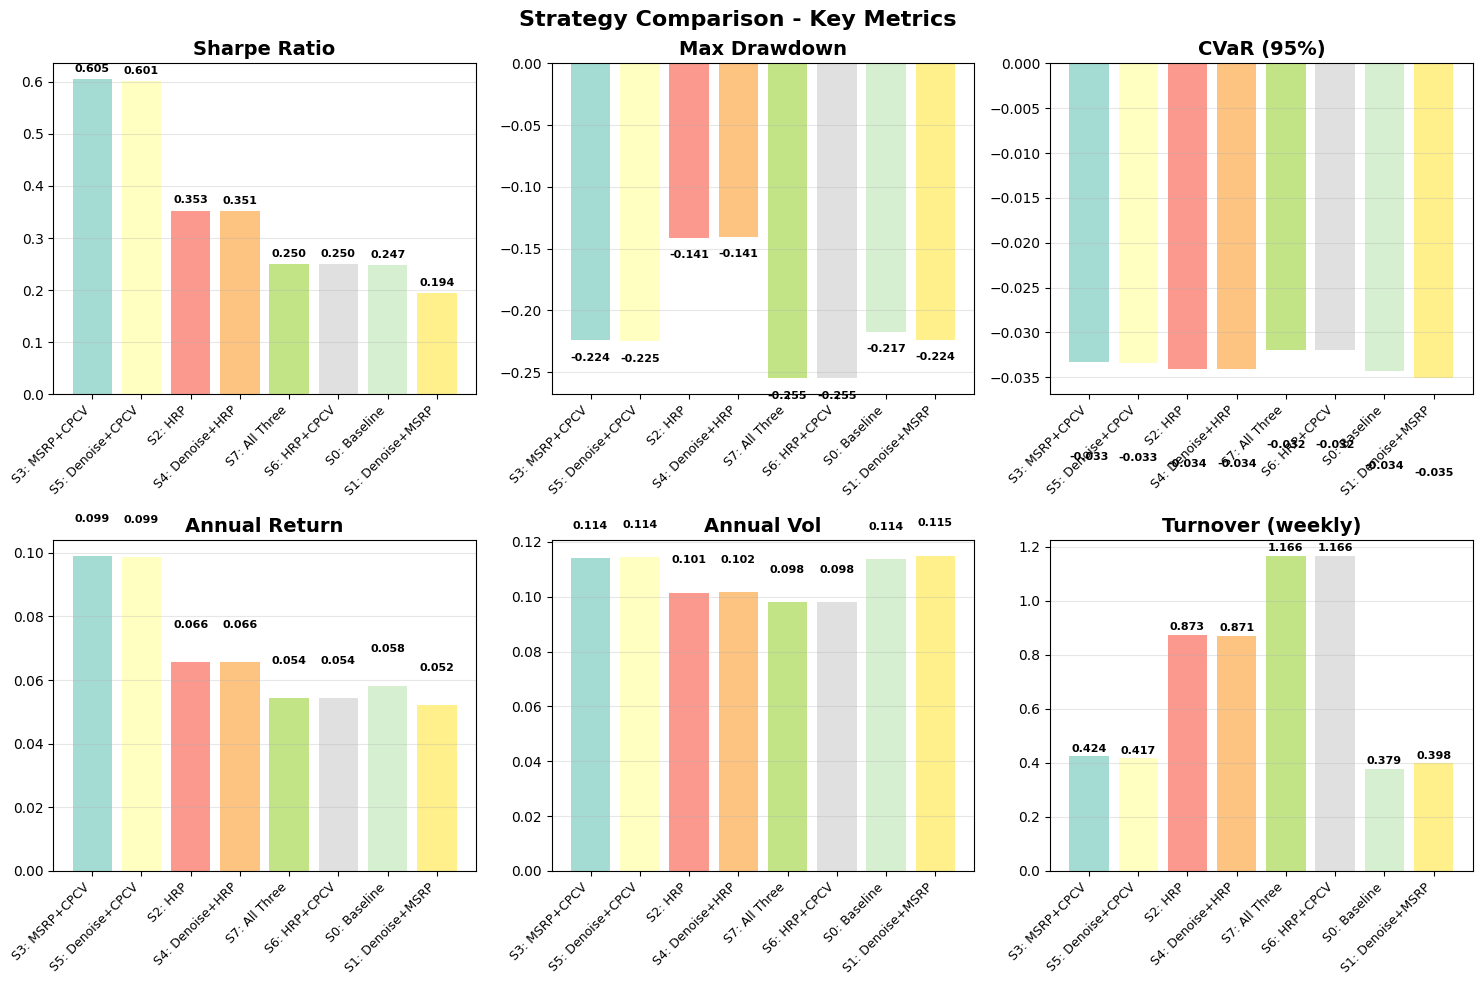

In [86]:
# Create shorter names for plotting
short_names = {
    'S0: Baseline MSRP': 'S0: Baseline',
    'S1: Denoising + MSRP': 'S1: Denoise+MSRP',
    'S2: HRP Only': 'S2: HRP',
    'S3: Backtesting Only (MSRP+CPCV)': 'S3: MSRP+CPCV',
    'S4: Denoising + HRP': 'S4: Denoise+HRP',
    'S5: Denoising + Backtesting (Denoised MSRP+CPCV)': 'S5: Denoise+CPCV',
    'S6: Clustering + Backtesting (HRP+CPCV)': 'S6: HRP+CPCV',
    'S7: All Three (Denoising+HRP+CPCV)': 'S7: All Three'
}

# Create a copy with short names for plotting
plot_df = comparison_df.copy()
plot_df.index = [short_names.get(idx, idx[:20] + '...') for idx in plot_df.index]

# Plot 1: Metrics comparison with wrapped labels
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

metrics_to_plot = ['Sharpe Ratio', 'Max Drawdown', 'CVaR (95%)',
                   'Annual Return', 'Annual Vol', 'Turnover (weekly)']

colors = plt.cm.Set3(np.linspace(0, 1, len(plot_df)))

for i, metric in enumerate(metrics_to_plot):
    ax = axes[i]

    # Create bar plot
    bars = ax.bar(range(len(plot_df)), plot_df[metric].values, color=colors, alpha=0.8)

    # Customize the plot
    ax.set_title(metric, fontsize=14, fontweight='bold')
    ax.set_xlabel('')
    ax.axhline(0, color='black', linestyle='-', linewidth=0.5)

    # Set x-tick labels with wrapping
    ax.set_xticks(range(len(plot_df)))
    ax.set_xticklabels(plot_df.index, rotation=45, ha='right', fontsize=9)

    # Add value labels on bars
    for j, (bar, val) in enumerate(zip(bars, plot_df[metric].values)):
        if not np.isnan(val):
            height = bar.get_height()
            va = 'bottom' if height >= 0 else 'top'
            offset = 0.01 if height >= 0 else -0.01
            ax.text(bar.get_x() + bar.get_width()/2., height + offset,
                   f'{val:.3f}', ha='center', va=va, fontsize=8, fontweight='bold')

    # Add grid for better readability
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Strategy Comparison - Key Metrics', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


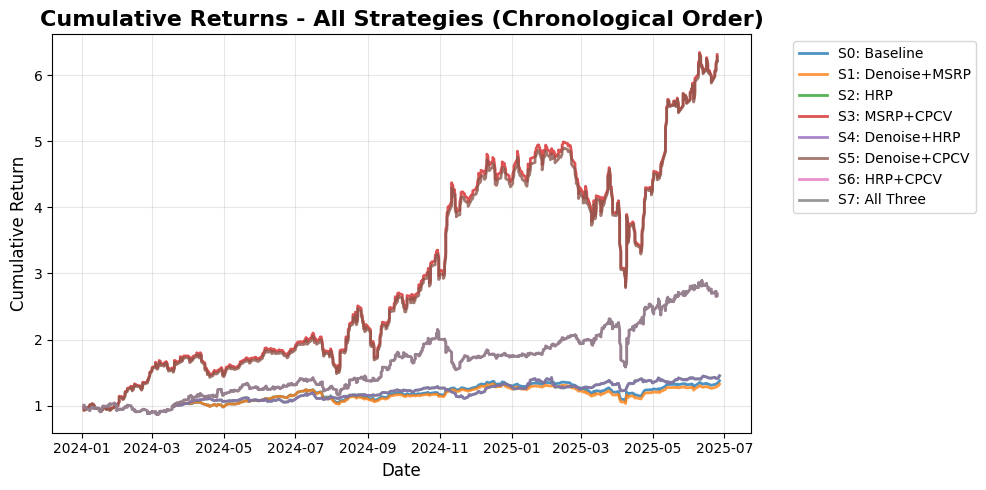

In [87]:
# Plot 2: Cumulative returns (sorted by date)
plt.figure(figsize=(10, 5))

# Get all returns series and sort them by date
for strategy_name, returns_series in all_returns_dict.items():
    if len(returns_series) > 0:
        # Sort by date
        returns_series = returns_series.sort_index()
        cum_returns = (1 + returns_series).cumprod()

        # Use short name for legend
        short_name = short_names.get(strategy_name, strategy_name[:20] + '...')

        # Plot with better styling
        plt.plot(cum_returns.index, cum_returns.values,
                label=short_name, linewidth=2, alpha=0.8)

plt.title('Cumulative Returns - All Strategies (Chronological Order)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Cumulative Return', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

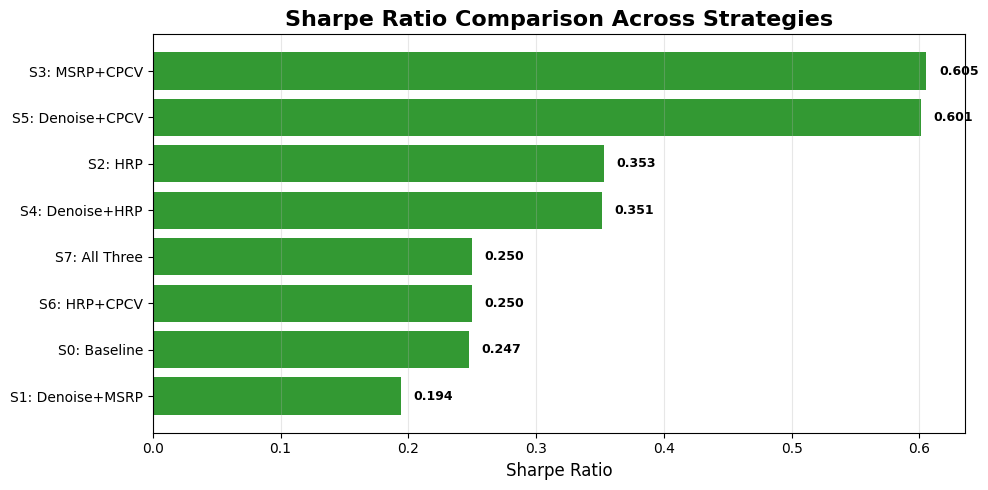

In [88]:
# Plot 3: Sharpe ratio comparison with confidence (horizontal bar chart)
plt.figure(figsize=(10, 5))

# Sort by Sharpe ratio
sharpe_sorted = plot_df.sort_values('Sharpe Ratio', ascending=True)
colors = ['green' if x > 0 else 'red' for x in sharpe_sorted['Sharpe Ratio']]

# Create horizontal bar chart
bars = plt.barh(sharpe_sorted.index, sharpe_sorted['Sharpe Ratio'], color=colors, alpha=0.8)

# Add value labels
for i, (bar, val) in enumerate(zip(bars, sharpe_sorted['Sharpe Ratio'])):
    if not np.isnan(val):
        x_pos = val + 0.01 if val >= 0 else val - 0.05
        plt.text(x_pos, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=9, fontweight='bold')

plt.xlabel('Sharpe Ratio', fontsize=12)
plt.title('Sharpe Ratio Comparison Across Strategies', fontsize=16, fontweight='bold')
plt.axvline(0, color='black', linestyle='-', linewidth=0.5)
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

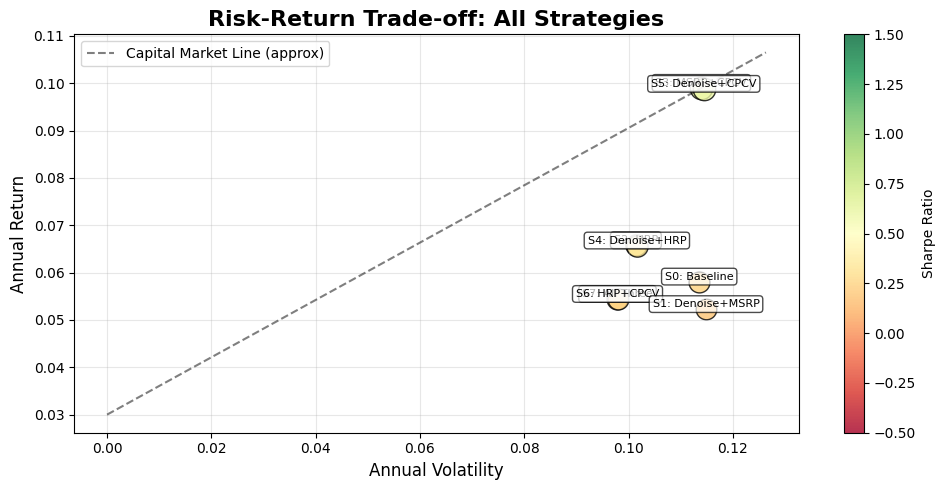

In [89]:
# Plot 4: Risk-Return scatter plot with better labels
plt.figure(figsize=(10, 5))

for strategy_name in plot_df.index:
    ret = plot_df.loc[strategy_name, 'Annual Return']
    vol = plot_df.loc[strategy_name, 'Annual Vol']
    sharpe = plot_df.loc[strategy_name, 'Sharpe Ratio']

    if not np.isnan(ret) and not np.isnan(vol):
        # Size points by Sharpe ratio
        size = 200 + 100 * max(0, sharpe)  # Larger points for higher Sharpe

        scatter = plt.scatter(vol, ret, s=size, c=[sharpe],
                             cmap='RdYlGn', vmin=-0.5, vmax=1.5,
                             alpha=0.8, edgecolors='black', linewidth=1)

        # Add strategy label
        plt.annotate(strategy_name, (vol, ret),
                    fontsize=8, ha='center', va='bottom',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

# Add colorbar
cbar = plt.colorbar(scatter, label='Sharpe Ratio')
cbar.ax.tick_params(labelsize=10)

# Add efficient frontier curve (approximate)
x = np.linspace(0, max(plot_df['Annual Vol'].dropna()) * 1.1, 100)
rf_rate = 0.03
y = rf_rate + x * max(plot_df['Sharpe Ratio'].dropna())  # Capital Market Line
plt.plot(x, y, 'k--', alpha=0.5, label='Capital Market Line (approx)')

plt.xlabel('Annual Volatility', fontsize=12)
plt.ylabel('Annual Return', fontsize=12)
plt.title('Risk-Return Trade-off: All Strategies', fontsize=16, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


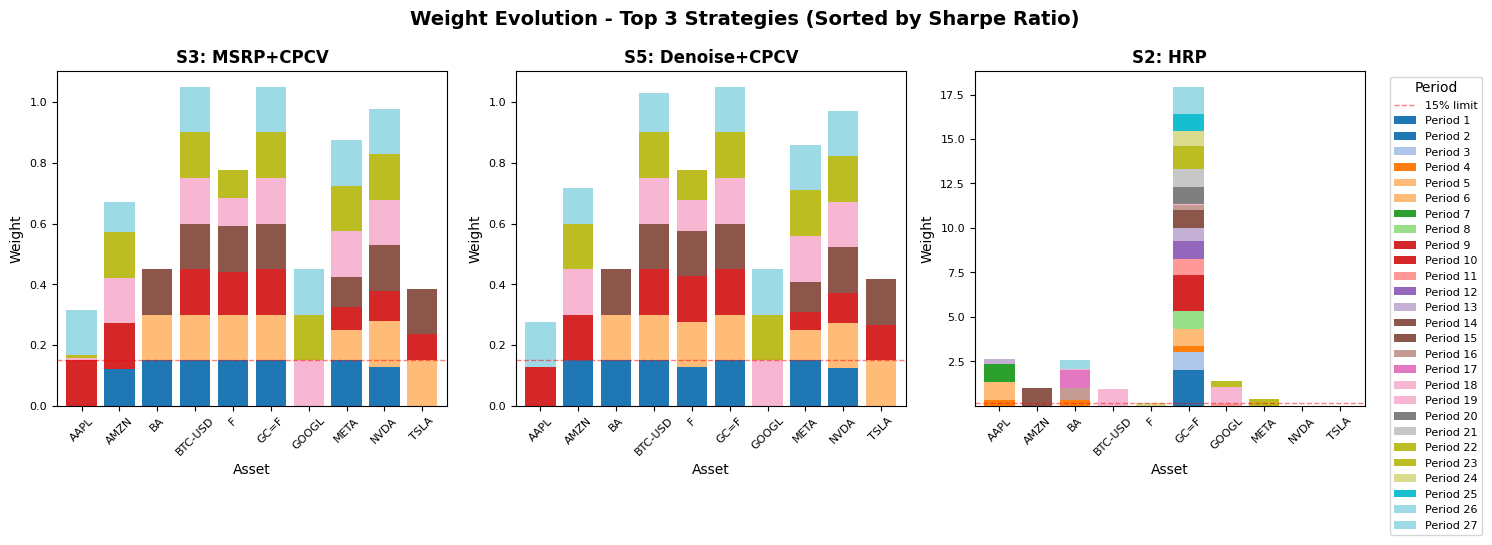

In [90]:
# Plot 5: Weight stability for top 3 strategies (with better formatting)
top_3 = plot_df.head(3).index.tolist()
# Map back to original names for weights dictionary
original_top_3 = []
for short in top_3:
    for orig, short_name in short_names.items():
        if short_name == short:
            original_top_3.append(orig)
            break

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, strategy_name in enumerate(original_top_3):
    weights_list = all_weights_dict[strategy_name]
    if len(weights_list) > 0:
        # Create weights DataFrame
        weights_df = pd.DataFrame([w.values for w in weights_list],
                                  columns=tickers,
                                  index=[f'Period {i+1}' for i in range(len(weights_list))])

        ax = axes[idx]

        # Plot stacked bar chart
        weights_df.T.plot(kind='bar', stacked=True, ax=ax,
                         colormap='tab20', width=0.8, legend=False)

        ax.set_title(f'{short_names[strategy_name]}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Asset', fontsize=10)
        ax.set_ylabel('Weight', fontsize=10)
        ax.tick_params(axis='x', rotation=45, labelsize=8)
        ax.tick_params(axis='y', labelsize=8)
        ax.axhline(0.15, color='red', linestyle='--', linewidth=1, alpha=0.5, label='15% limit')

        # Add legend for periods
        if idx == 2:  # Only add legend for last subplot
            ax.legend(title='Period', bbox_to_anchor=(1.05, 1), fontsize=8)

plt.suptitle('Weight Evolution - Top 3 Strategies (Sorted by Sharpe Ratio)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

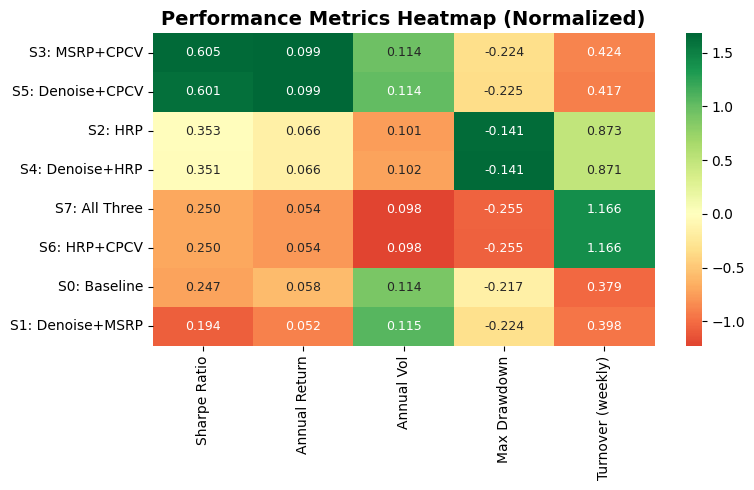

IMPROVEMENT ANALYSIS

Baseline (S0): Sharpe = 0.2474, MaxDD = -0.2172

S1: Denoising + MSRP:
  Sharpe: 0.1940 (-21.6% vs baseline)
  MaxDD: -0.2237 (-3.0% vs baseline)

S2: HRP Only:
  Sharpe: 0.3528 (+42.6% vs baseline)
  MaxDD: -0.1410 (+35.1% vs baseline)

S3: Backtesting Only (MSRP+CPCV):
  Sharpe: 0.6054 (+144.7% vs baseline)
  MaxDD: -0.2242 (-3.2% vs baseline)

S4: Denoising + HRP:
  Sharpe: 0.3515 (+42.1% vs baseline)
  MaxDD: -0.1406 (+35.2% vs baseline)

S5: Denoising + Backtesting (Denoised MSRP+CPCV):
  Sharpe: 0.6012 (+143.0% vs baseline)
  MaxDD: -0.2250 (-3.6% vs baseline)

S6: Clustering + Backtesting (HRP+CPCV):
  Sharpe: 0.2495 (+0.9% vs baseline)
  MaxDD: -0.2550 (-17.4% vs baseline)

S7: All Three (Denoising+HRP+CPCV):
  Sharpe: 0.2495 (+0.9% vs baseline)
  MaxDD: -0.2549 (-17.4% vs baseline)


In [91]:
# Plot 6: Performance summary heatmap
plt.figure(figsize=(12, 6))

# Select key metrics for heatmap
heatmap_metrics = ['Sharpe Ratio', 'Annual Return', 'Annual Vol', 'Max Drawdown', 'Turnover (weekly)']
heatmap_data = plot_df[heatmap_metrics].copy()

# Normalize for better visualization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
heatmap_normalized = pd.DataFrame(
    scaler.fit_transform(heatmap_data),
    index=heatmap_data.index,
    columns=heatmap_data.columns
)

# Create heatmap
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_normalized, annot=plot_df[heatmap_metrics].round(3),
            fmt='.3f', cmap='RdYlGn', center=0,
            xticklabels=heatmap_metrics, yticklabels=heatmap_data.index,
            annot_kws={'size': 9})
plt.title('Performance Metrics Heatmap (Normalized)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print improvement analysis with better formatting
print("IMPROVEMENT ANALYSIS")
print("="*80)

baseline_sharpe = comparison_df.loc['S0: Baseline MSRP', 'Sharpe Ratio']
baseline_dd = comparison_df.loc['S0: Baseline MSRP', 'Max Drawdown']

print(f"\nBaseline (S0): Sharpe = {baseline_sharpe:.4f}, MaxDD = {baseline_dd:.4f}")

for strategy in ['S1: Denoising + MSRP', 'S2: HRP Only', 'S3: Backtesting Only (MSRP+CPCV)',
                 'S4: Denoising + HRP', 'S5: Denoising + Backtesting (Denoised MSRP+CPCV)',
                 'S6: Clustering + Backtesting (HRP+CPCV)', 'S7: All Three (Denoising+HRP+CPCV)']:
    if strategy in comparison_df.index:
        sharpe_imp = (comparison_df.loc[strategy, 'Sharpe Ratio'] - baseline_sharpe) / abs(baseline_sharpe) * 100
        dd_imp = (comparison_df.loc[strategy, 'Max Drawdown'] - baseline_dd) / abs(baseline_dd) * 100

        print(f"\n{strategy}:")
        print(f"  Sharpe: {comparison_df.loc[strategy, 'Sharpe Ratio']:.4f} ({sharpe_imp:+.1f}% vs baseline)")
        print(f"  MaxDD: {comparison_df.loc[strategy, 'Max Drawdown']:.4f} ({dd_imp:+.1f}% vs baseline)")

In [92]:
# ============================================================================
# PART 9: STATISTICAL SUMMARY
# ============================================================================

print("\n" + "="*80)
print("STATISTICAL SUMMARY")
print("="*80)

# Best and worst performers
best_sharpe = comparison_df['Sharpe Ratio'].idxmax()
worst_sharpe = comparison_df['Sharpe Ratio'].idxmin()
best_return = comparison_df['Annual Return'].idxmax()
lowest_risk = comparison_df['Annual Vol'].idxmin()
lowest_dd = comparison_df['Max Drawdown'].idxmax()  # Less negative is better

print(f"\nBest Sharpe Ratio: {best_sharpe} ({comparison_df.loc[best_sharpe, 'Sharpe Ratio']:.4f})")
print(f"Worst Sharpe Ratio: {worst_sharpe} ({comparison_df.loc[worst_sharpe, 'Sharpe Ratio']:.4f})")
print(f"Highest Return: {best_return} ({comparison_df.loc[best_return, 'Annual Return']:.4f})")
print(f"Lowest Risk: {lowest_risk} ({comparison_df.loc[lowest_risk, 'Annual Vol']:.4f})")
print(f"Best Drawdown: {lowest_dd} ({comparison_df.loc[lowest_dd, 'Max Drawdown']:.4f})")

# Compare improvement strategies
print("\nImprovement Analysis:")
baseline_sharpe = comparison_df.loc['S0: Baseline MSRP', 'Sharpe Ratio']
baseline_dd = comparison_df.loc['S0: Baseline MSRP', 'Max Drawdown']

for strategy in ['S1: Denoising + MSRP', 'S2: HRP Only', 'S3: Backtesting Only (MSRP+CPCV)',
                 'S4: Denoising + HRP', 'S5: Denoising + Backtesting (Denoised MSRP+CPCV)',
                 'S6: Clustering + Backtesting (HRP+CPCV)', 'S7: All Three (Denoising+HRP+CPCV)']:
    if strategy in comparison_df.index:
        sharpe_imp = (comparison_df.loc[strategy, 'Sharpe Ratio'] - baseline_sharpe) / abs(baseline_sharpe) * 100
        dd_imp = (comparison_df.loc[strategy, 'Max Drawdown'] - baseline_dd) / abs(baseline_dd) * 100
        print(f"\n{strategy}:")
        print(f"  Sharpe improvement: {sharpe_imp:.1f}%")
        print(f"  Drawdown improvement: {dd_imp:.1f}%")


STATISTICAL SUMMARY

Best Sharpe Ratio: S3: Backtesting Only (MSRP+CPCV) (0.6054)
Worst Sharpe Ratio: S1: Denoising + MSRP (0.1940)
Highest Return: S3: Backtesting Only (MSRP+CPCV) (0.0990)
Lowest Risk: S7: All Three (Denoising+HRP+CPCV) (0.0979)
Best Drawdown: S4: Denoising + HRP (-0.1406)

Improvement Analysis:

S1: Denoising + MSRP:
  Sharpe improvement: -21.6%
  Drawdown improvement: -3.0%

S2: HRP Only:
  Sharpe improvement: 42.6%
  Drawdown improvement: 35.1%

S3: Backtesting Only (MSRP+CPCV):
  Sharpe improvement: 144.7%
  Drawdown improvement: -3.2%

S4: Denoising + HRP:
  Sharpe improvement: 42.1%
  Drawdown improvement: 35.2%

S5: Denoising + Backtesting (Denoised MSRP+CPCV):
  Sharpe improvement: 143.0%
  Drawdown improvement: -3.6%

S6: Clustering + Backtesting (HRP+CPCV):
  Sharpe improvement: 0.9%
  Drawdown improvement: -17.4%

S7: All Three (Denoising+HRP+CPCV):
  Sharpe improvement: 0.9%
  Drawdown improvement: -17.4%


## Step 5

In [93]:
# Define the securities and period
tickers = [
    "AAPL",     # Apple
    "AMZN",     # Amazon
    "BA",       # Boeing
    "BTC-USD",  # Bitcoin
    "F",        # Ford
    "GC=F",     # Gold
    "GOOGL",    # Google
    "META",     # Meta
    "NVDA",     # Nvidia
    "TSLA"      # Tesla
  ]

start_date = "2024-01-01"
end_date = "2025-07-31" # Extended to include July 2025

# Download weekly data (adjusted close prices)
data = yf.download(tickers, start=start_date, end=end_date)

if 'Adj Close' in data.columns.get_level_values(0):
    prices = data['Adj Close']
elif 'Close' in data.columns.get_level_values(0):
    prices = data['Close']

# Check if we have data for all tickers
print(f"\nData shape: {prices.shape}")
print('BTC has prices on Saturday and Sunday')

# Drop rows have no stock prices (Remove BTC prices on Saturday and Sunday)
prices = prices.dropna()

# Calculate weekly returns
returns = prices.pct_change().dropna()

print('\nData after cleaning')
print(f"Returns shape: {returns.shape}")

[*********************100%***********************]  10 of 10 completed



Data shape: (577, 10)
BTC has prices on Saturday and Sunday

Data after cleaning
Returns shape: (394, 10)


In [94]:
# Calculate July 2025 performance
july_start = "2025-07-01"
july_end = "2025-07-31"

# Get July data
july_prices = prices.loc[july_start:july_end]
july_returns = july_prices.pct_change().dropna()

In [95]:
# PORTFOLIO OPTIMIZATION FUNCTIONS

def msrp_weights(returns, max_weight=0.15, rf_rate=0.03):
    """
    Maximum Sharpe Ratio Portfolio with constraints
    """
    mean_returns = returns.mean().values
    cov_matrix = returns.cov().values + 1e-8 * np.eye(len(returns.columns))
    n_assets = len(returns.columns)
    daily_rf = rf_rate / 252

    def negative_sharpe(weights):
        port_return = np.dot(weights, mean_returns)
        port_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
        if port_vol < 1e-8:
            return 1e8
        sharpe = (port_return - daily_rf) / port_vol
        return -sharpe

    constraints = [{'type': 'eq', 'fun': lambda x: np.sum(x) - 1}]
    bounds = [(0, max_weight) for _ in range(n_assets)]
    initial_weights = np.array([1/n_assets] * n_assets)
    initial_weights = np.minimum(initial_weights, max_weight)
    initial_weights = initial_weights / np.sum(initial_weights)

    result = minimize(
        negative_sharpe,
        initial_weights,
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={'ftol': 1e-8, 'maxiter': 1000}
    )

    if result.success:
        return result.x
    else:
        return initial_weights

In [96]:
# CPCV

def cpcv_weights(returns, n_folds=5, test_folds=2):
    """
    Calculate weights using Combinatorial Purged Cross-Validation
    """
    n = len(returns)
    fold_size = n // n_folds
    all_weights = []

    # Create fold indices
    fold_indices = []
    for i in range(n_folds):
        start = i * fold_size
        end = min((i + 1) * fold_size, n)
        if end - start > 5:  # Only use folds with enough data
            fold_indices.append(list(range(start, end)))

    if len(fold_indices) < n_folds:
        n_folds = len(fold_indices)
        print(f"Adjusted to {n_folds} folds")

    # Generate test fold combinations
    test_combs = list(combinations(range(n_folds), test_folds))

    # Limit combinations for performance
    if len(test_combs) > 10:
        np.random.seed(42)
        test_combs = [test_combs[i] for i in np.random.choice(len(test_combs), 10, replace=False)]

    for test_folds_idx in test_combs:
        # Get test indices
        test_idx = []
        for fold_idx in test_folds_idx:
            test_idx.extend(fold_indices[fold_idx])

        # Training indices (purged)
        train_idx = []
        for i in range(n_folds):
            if i not in test_folds_idx:
                # Add purge/embargo (skip data adjacent to test)
                fold_start = fold_indices[i][0]
                fold_end = fold_indices[i][-1]

                # Check if too close to test
                too_close = False
                for t_idx in test_idx:
                    if abs(t_idx - fold_end) < 10 or abs(fold_start - t_idx) < 10:
                        too_close = True
                        break

                if not too_close:
                    train_idx.extend(fold_indices[i])

        if len(train_idx) < 20 or len(test_idx) < 5:
            continue

        # Train on this split
        train_data = returns.iloc[train_idx]

        try:
            weights = msrp_weights(train_data)
            all_weights.append(weights)
        except:
            continue

    if len(all_weights) == 0:
        print("Warning: CPCV failed, using standard MSRP")
        return msrp_weights(returns)

    # Average weights across all splits
    avg_weights = np.mean(all_weights, axis=0)
    return avg_weights

In [97]:
# PORTFOLIO PERFORMANCE METRICS

def portfolio_performance(weights, returns, rf_rate=0.03):
    """
    Calculate comprehensive performance metrics
    """
    # Daily portfolio returns
    port_returns = returns @ weights

    # Basic metrics
    total_return = (1 + port_returns).prod() - 1
    annual_return = (1 + total_return) ** (252/len(port_returns)) - 1
    volatility = port_returns.std() * np.sqrt(252)
    sharpe = (port_returns.mean() / port_returns.std()) * np.sqrt(252) if port_returns.std() > 0 else 0

    # Maximum drawdown
    cumulative = (1 + port_returns).cumprod()
    running_max = cumulative.expanding().max()
    drawdown = (cumulative - running_max) / running_max
    max_drawdown = drawdown.min()

    # CVaR (Expected Shortfall)
    var_95 = np.percentile(port_returns, 5)
    cvar_95 = port_returns[port_returns <= var_95].mean()

    # Sortino ratio
    downside_returns = port_returns[port_returns < 0]
    downside_vol = downside_returns.std() * np.sqrt(252) if len(downside_returns) > 0 else 0
    sortino = (annual_return - rf_rate) / downside_vol if downside_vol > 0 else 0

    return {
        'Total Return': total_return,
        'Annual Return': annual_return,
        'Volatility': volatility,
        'Sharpe Ratio': sharpe,
        'Max Drawdown': max_drawdown,
        'CVaR (95%)': cvar_95,
        'Sortino Ratio': sortino
    }


In [98]:
# CALCULATE PORTFOLIOS

# Baseline MSRP (Step 1)
baseline_weights = msrp_weights(returns)

# S3: MSRP with CPCV
s3_weights = cpcv_weights(returns)

In [99]:
# COMPARE WEIGHTS

weight_comparison = pd.DataFrame({
    'Baseline MSRP': baseline_weights,
    'S3 (MSRP+CPCV)': s3_weights
}, index=tickers)

print(weight_comparison.round(4))

# Calculate concentration
baseline_top3 = sum(sorted(baseline_weights, reverse=True)[:3]) * 100
s3_top3 = sum(sorted(s3_weights, reverse=True)[:3]) * 100

print(f"\nTop 3 Asset Concentration:")
print(f"Baseline MSRP: {baseline_top3:.1f}%")
print(f"S3 (MSRP+CPCV): {s3_top3:.1f}%")

         Baseline MSRP  S3 (MSRP+CPCV)
AAPL            0.0510          0.0429
AMZN            0.1500          0.1110
BA              0.0000          0.0643
BTC-USD         0.1500          0.1462
F               0.0490          0.0959
GC=F            0.1500          0.1500
GOOGL           0.1500          0.1356
META            0.1500          0.1071
NVDA            0.1500          0.1257
TSLA            0.0000          0.0214

Top 3 Asset Concentration:
Baseline MSRP: 45.0%
S3 (MSRP+CPCV): 43.2%


In [100]:
# JULY 2025 OUT-OF-SAMPLE TEST

test_returns = july_returns

# Calculate July performance
baseline_july_returns = test_returns @ baseline_weights
s3_july_returns = test_returns @ s3_weights

baseline_perf = portfolio_performance(baseline_weights, test_returns)
s3_perf = portfolio_performance(s3_weights, test_returns)

# Create comparison table
results_df = pd.DataFrame({
    'Baseline MSRP': baseline_perf,
    'S3 (Optimal)': s3_perf
})

# Calculate improvement
improvement = {}
for metric in results_df.index:
    baseline_val = results_df.loc[metric, 'Baseline MSRP']
    s3_val = results_df.loc[metric, 'S3 (Optimal)']

    if metric in ['Volatility', 'Max Drawdown', 'CVaR (95%)']:
        # Lower is better for these metrics
        impr = ((baseline_val - s3_val) / abs(baseline_val)) * 100 if baseline_val != 0 else 0
    else:
        # Higher is better for these metrics
        impr = ((s3_val - baseline_val) / abs(baseline_val)) * 100 if baseline_val != 0 else 0

    improvement[metric] = impr

results_df.loc['Improvement (%)'] = improvement

# Display results
pd.set_option('display.float_format', '{:.4f}'.format)
print("\n", results_df.round(4))


                  Baseline MSRP  S3 (Optimal)
Total Return            0.0569        0.0550
Annual Return           1.0090        0.9631
Volatility              0.0869        0.0972
Sharpe Ratio            8.0848        6.9982
Max Drawdown           -0.0095       -0.0093
CVaR (95%)             -0.0070       -0.0079
Sortino Ratio          26.6101       19.3743
Improvement (%)            NaN           NaN


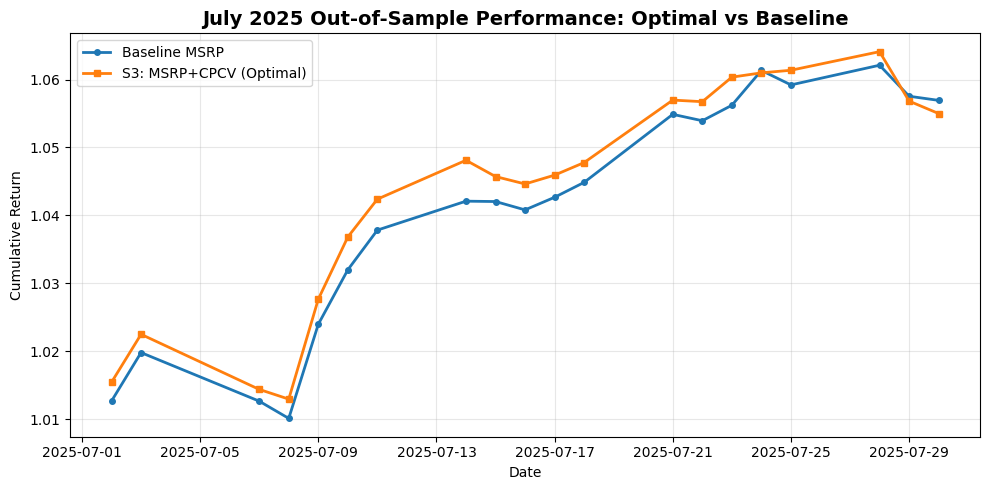

In [101]:
# VISUALIZATION

# Plot cumulative returns
plt.figure(figsize=(10, 5))

baseline_cumulative = (1 + baseline_july_returns).cumprod()
s3_cumulative = (1 + s3_july_returns).cumprod()

plt.plot(baseline_cumulative.index, baseline_cumulative.values,
         label='Baseline MSRP', linewidth=2, marker='o', markersize=4)
plt.plot(s3_cumulative.index, s3_cumulative.values,
         label='S3: MSRP+CPCV (Optimal)', linewidth=2, marker='s', markersize=4)

plt.title('July 2025 Out-of-Sample Performance: Optimal vs Baseline', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


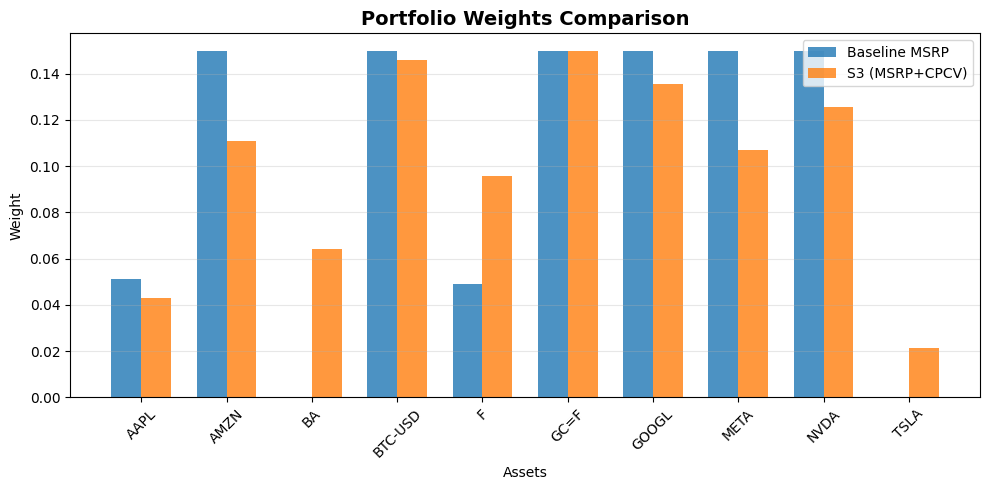

In [102]:
# Plot weight comparison
plt.figure(figsize=(10, 5))
x = np.arange(len(tickers))
width = 0.35

plt.bar(x - width/2, baseline_weights, width, label='Baseline MSRP', alpha=0.8)
plt.bar(x + width/2, s3_weights, width, label='S3 (MSRP+CPCV)', alpha=0.8)

plt.xlabel('Assets')
plt.ylabel('Weight')
plt.title('Portfolio Weights Comparison', fontsize=14, fontweight='bold')
plt.xticks(x, tickers, rotation=45)
plt.legend()
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()